# S3DXRD processing first step: dataset creation, segmentation and peak labelling

Written by James Ball, Haixing Fang and Jon Wright

Last updated: 21/02/2025

Outside ESRF: download [install_ImageD11_from_git.py](https://github.com/FABLE-3DXRD/ImageD11/tree/master/ImageD11/nbGui/install_ImageD11_from_git.py), and update the path in the next cell:

In [17]:
# this cell is tagged with 'parameters'
# to view the tag, select the cell, then find the settings gear icon (right or left sidebar) and look for Cell Tags

# python environment stuff
IMAGED11_PATH = '/home/esrf/charles27/Code/ImageD11/'  # means do not use git, otherwise "ImageD11" or "ImageD11_version_xx", etc
CHECKOUT_PATH = None  # None means guess, or you can specify a folder for the checkout

# Experts : update these files for your detector if you need to
maskfile = "/data/visitor/ma7380/id11/20260901/PROCESSED_DATA/calib/eiger_mask_E-08-0144_20250819.edf"
# old papermill tests still use e2dx + e2dy
#  if you give e2dxfile, this is used. Otherwise it takes the detector h5 below.
e2dxfile = "/data/visitor/ma7380/id11/20260901/PROCESSED_DATA/calib/e2dx_20250819.edf"
e2dyfile = "/data/visitor/ma7380/id11/20260901/PROCESSED_DATA/calib/e2dy_20250819.edf"
# For the future easier to have one detectorh5 (so you can't mix up x/y).
# detectorh5 = "/data/id11/nanoscope/Eiger/spatial_20250826_LJ/newSpatial_20250819.h5"
detector = 'eiger'
omegamotor = 'diffrz'
dtymotor = 'diffty'

# do we segment on the local machine or on slurm?
segment_local = True
ncores_local = 48

# Default segmentation options
options = { 'cut' : 1, 'pixels_in_spot' : 3, 'howmany' : 100000 }
normalise_intensities_to_monitor = False
monitor_name = 'fpico4'

# EXPERTS: These can be provided as papermill parameters. Users, leave these as None for now...
dataroot = '/data/visitor/ma7056/id11/20260624/RAW_DATA/'
analysisroot = '/data/visitor/ma7056/id11/20260624/PROCESSED_DATA/'
sample = 'pureIron_2_heating_3'
dataset = 'sff_after_20min0'

In [2]:
if IMAGED11_PATH is not None:
    exec(open('/data/id11/nanoscope/install_ImageD11_from_git.py').read())
    PYTHONPATH=setup_ImageD11_from_git(CHECKOUT_PATH, IMAGED11_PATH)
else:
    import site
    PYTHONPATH = site.getsitepackages()[0]
    print(PYTHONPATH)

# Setting path via: 
sys.path.insert(0, /home/esrf/charles27/Code/ImageD11/ )
# Running from: /home/esrf/charles27/Code/ImageD11/ImageD11/__init__.py


In [3]:
# Import needed packages
import pprint
import numpy as np
from matplotlib import pyplot as plt

import ImageD11.sinograms.dataset
import ImageD11.sinograms.lima_segmenter
import ImageD11.sinograms.assemble_label
import ImageD11.sinograms.properties
import ImageD11.nbGui.nb_utils as utils
from ImageD11.nbGui import segmenter_gui

%matplotlib ipympl

In [4]:
# Set up the file paths. Edit this if you are not at ESRF or not using the latest data policy.
if dataroot is None:
    dataroot, analysisroot = segmenter_gui.guess_ESRF_paths() 

if len(dataroot)==0:
    print("Please fix in the dataroot and analysisroot folder names above!!")
    
print('dataroot =',repr(dataroot))
print('analysisroot =',repr(analysisroot))

dataroot = '/data/visitor/ma7056/id11/20260624/RAW_DATA/'
analysisroot = '/data/visitor/ma7056/id11/20260624/PROCESSED_DATA/'


In [5]:
# List the samples available:
segmenter_gui.printsamples(dataroot)

Samples:
	 CeO2
	CeO2_Friday
	Si
	Si_Sunday
	Si_cube
	WAuCross
	ind_iron
	oven_calib
	oven_test
	pureIron1_recryst
	pureIron_1
	pureIron_1_430C
	pureIron_2
	pureIron_2_heating_2
	pureIron_2_heating_3
	recryst_heating_1


In [6]:
# USER: Decide which sample
if sample is None:
    sample = 'FeAu_0p5_tR_nscope'

In [7]:
# List the datasets for that sample:
segmenter_gui.printdatasets( dataroot, sample )

Datsets:
	 0001
	dct
	sff_after_20min0
	sff_after_20min1
	sff_after_20min10
	sff_after_20min11
	sff_after_20min12
	sff_after_20min13
	sff_after_20min14
	sff_after_20min15
	sff_after_20min16
	sff_after_20min17
	sff_after_20min18
	sff_after_20min19
	sff_after_20min2
	sff_after_20min20
	sff_after_20min21
	sff_after_20min22
	sff_after_20min23
	sff_after_20min24
	sff_after_20min25
	sff_after_20min26
	sff_after_20min27
	sff_after_20min28
	sff_after_20min29
	sff_after_20min3
	sff_after_20min30
	sff_after_20min31
	sff_after_20min32
	sff_after_20min33
	sff_after_20min34
	sff_after_20min35
	sff_after_20min36
	sff_after_20min37
	sff_after_20min38
	sff_after_20min39
	sff_after_20min4
	sff_after_20min40
	sff_after_20min41
	sff_after_20min42
	sff_after_20min43
	sff_after_20min44
	sff_after_20min45
	sff_after_20min46
	sff_after_20min47
	sff_after_20min48
	sff_after_20min49
	sff_after_20min5
	sff_after_20min6
	sff_after_20min7
	sff_after_20min8
	sff_after_20min9


In [8]:
# USER: Decide which dataset
if dataset is None:
    dataset = "top_100um"

## Example demo to see how a frame is segmented for one dataset:

In [9]:
# create ImageD11 dataset object
ds = ImageD11.sinograms.dataset.DataSet(dataroot=dataroot,
                                        analysisroot=analysisroot,
                                        sample=sample,
                                        dset=dataset,
                                        detector=detector,
                                        omegamotor=omegamotor,
                                        dtymotor=dtymotor
                                       )
ds.import_all()  # Can use scans = [f'{scan}.1' for scan in range(1,102)] )
ds.maskfile = maskfile
if e2dxfile is not None:
    ds.e2dxfile = e2dxfile
    ds.e2dyfile = e2dyfile
else:
    ds.detectorh5 = detectorh5
ds.save()

Using frame 144347 from scan 1.1


interactive(children=(IntSlider(value=1, description='Cut:', max=200), IntSlider(value=3, description='Pixels …

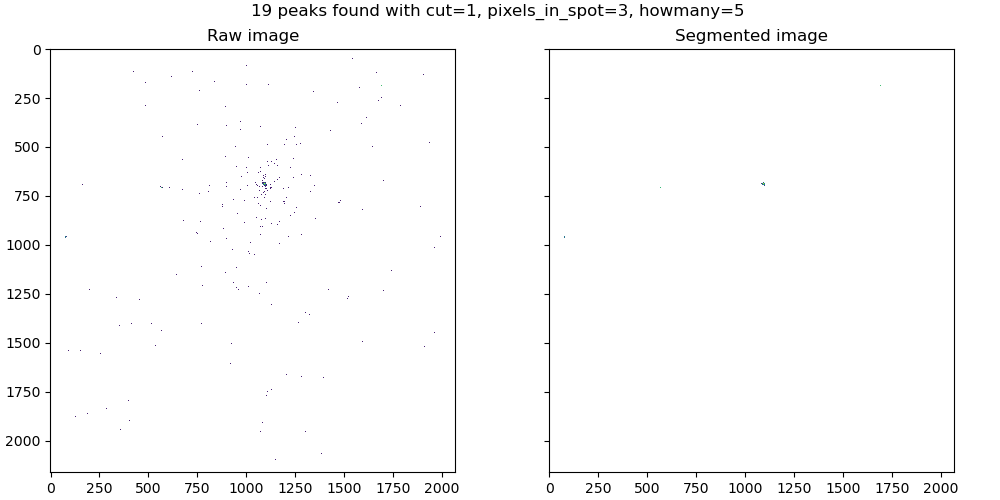

In [10]:
ui = segmenter_gui.SegmenterGui(ds, **options )

**IMPORTANT NOTE**

If you changed the segmentation parameters from the defaults, you **MUST** manually update them to match in the first cell under `options = {'cut': ...`

If you do not do this, **Papermill** (batch processing other layers) will **not** use your updated values!

In [11]:
options = ui.getopts()

options =  {'cut': 1, 'pixels_in_spot': 3, 'howmany': 100000}


# Sparse file creation

In [12]:
# create batch file to send to SLURM cluster
sbat = ImageD11.sinograms.lima_segmenter.setup(ds.dsfile, **ui.getopts(), pythonpath=PYTHONPATH)
segment = True
if sbat is None:
    segment = False
    print('Not segmenting, only asembling the segmented images into the dataset structure')
print(sbat)

options =  {'cut': 1, 'pixels_in_spot': 3, 'howmany': 100000}
cut 1
howmany 100000
pixels_in_spot 3
maskfile /data/visitor/ma7380/id11/20260901/PROCESSED_DATA/calib/eiger_mask_E-08-0144_20250819.edf
bgfile 
cores_per_job 16
files_per_core 4
total files to process 65 done 65
Not segmenting, only asembling the segmented images into the dataset structure
None


In [13]:
if segment:
    if segment_local:
        ImageD11.sinograms.lima_segmenter.sbatchlocal(sbat, cores=ncores_local)
    else:
        utils.slurm_submit_and_wait(sbat, 60)

# Peak labeling

In [14]:
# label sparse peaks

ImageD11.sinograms.assemble_label.main(ds.dsfile)

Harvesting /data/visitor/ma7056/id11/20260624/RAW_DATA/pureIron_2_heating_3/pureIron_2_heating_3_sff_after_20min0/pureIron_2_heating_3_sff_after_20min0.h5: 1.1, 
Loading pixels: 1.1, 


In [15]:
# generate peaks table

ImageD11.sinograms.properties.main(ds.dsfile, options={'algorithm': 'lmlabel', 'wtmax': 70000, 'save_overlaps': False})

read ds /data/visitor/ma7056/id11/20260624/PROCESSED_DATA/pureIron_2_heating_3/pureIron_2_heating_3_sff_after_20min0/pureIron_2_heating_3_sff_after_20min0_dataset.h5 : 0.041287 /s
Nscans 400
Options {'algorithm': 'lmlabel', 'wtmax': 70000, 'save_overlaps': False, 'nproc': 96}


 99%|████████████████████████████████████████████████████████████████████████████████████ | 95/96 [00:00<00:00, 1472.48it/s]


1063420 label and pair : 4.634723 /s
.................................................................................................................................................................................152422 connected components : 0.607401 /s
write hdf5 : 0.021407 /s
Trying to clean up shared memory


# Intensity normalisation
You can optionally normalise your observed intensities to a monitor column, such as a pico, if you had one in the beam path.

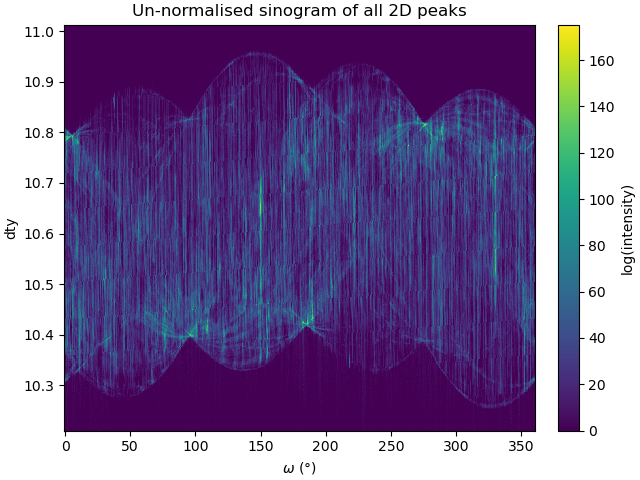

In [16]:
fig, ax = plt.subplots(layout='constrained')
im, om_edges, dty_edges = ds.sinohist(np.log(ds.pk2d['sum_intensity']), ds.pk2d['omega'], ds.pk2d['dty'], return_edges=True)
pcm = ax.pcolormesh(om_edges, dty_edges, im.T)
ax.set(xlabel=r'$\omega~(\degree)$', ylabel='dty', title='Un-normalised sinogram of all 2D peaks')
cax = fig.colorbar(pcm, ax=ax, label='log(intensity)')
plt.show()

Let's look at an image of the monitor signal across (dty, omega)

In [18]:
if normalise_intensities_to_monitor:
    monitor_per_frame = ds.get_monitor(monitor_name)

    fig, ax = plt.subplots(layout='constrained')
    pcm = ax.pcolormesh(om_edges, dty_edges, monitor_per_frame)
    ax.set(xlabel=r'$\omega~(\degree)$', ylabel='dty', title='Monitor column')
    cax = fig.colorbar(pcm, ax=ax, label='Monitor')
    plt.show()

To normalise to a monitor signal, we need to choose a "reference" monitor value that we scale to.
A good choice may be `np.mean(monitor_per_frame)`

We then compute `scale_factor_per_frame = np.mean(monitor_per_frame) / monitor_per_frame`  
We then multiply the observed intensities by `scale_factor_per_frame`

You can choose which function to use to generate the "reference" monitor value, for example:

`ds.set_monitor(monitor_name='fpico6', ref_value_func=np.mean)`

In [19]:
if normalise_intensities_to_monitor:
    # ensure no monitor currently set
    ds.monitor = None
    ds.monitor_ref = None
    ds.reset_peaks_cache()

    fig, ax = plt.subplots(layout='constrained')
    im, om_edges, dty_edges = ds.sinohist(ds.pk2d['sum_intensity'], ds.pk2d['omega'], ds.pk2d['dty'], return_edges=True)
    ax.plot(dty_edges, im.sum(axis=0), label='before scaling')
    
    # here we set the monitor
    ds.set_monitor(monitor_name, ref_value_func=np.mean)

    im, om_edges, dty_edges = ds.sinohist(ds.pk2d['sum_intensity'], ds.pk2d['omega'], ds.pk2d['dty'], return_edges=True)
    ax.plot(dty_edges, im.sum(axis=0), label='after scaling')
    ax.legend()
    ax.set(xlabel='dty', ylabel='intensity', title='Before vs after setting monitor')
    plt.show()
    
    # save the choice of monitor to disk
    ds.save()

# Finished segmenting!

You can now choose between two different indexing routes: tomographic (tomo) and point-by-point (pbp).  
Tomo gives you better grain shapes, but can't handle highly deformed samples.  
Point-by-point can only give you convex grain shapes (less accurate) but can handle high levels of deformation.  
Both techniques will join back together during the strain refinement stage (notebook 3).  
Therefore notebooks 4 and onwards should work from either the tomo or pbp route.